# Olist — Vendas, Logística e Satisfação do Cliente
**Análise exploratória (EDA)** | Dados reais de ~100 mil pedidos de um marketplace brasileiro (2016–2018)

**Pergunta central:** o que afeta a receita e a experiência do cliente, e o que a empresa deveria fazer a respeito?

**Escopo adotado**
- Pedidos com status `delivered` e compra entre **jan/2017 e ago/2018** (meses completos; 2016 e set–out/2018 têm pouquíssimos pedidos).
- Receita = soma de `price` dos itens (frete analisado à parte).
- Cliente = `customer_unique_id` (o `customer_id` muda a cada pedido).

**Fonte dos dados:** a camada limpa vem das views SQL (`sql/01_views.sql`). Itens, pagamentos e reviews são agregados por pedido antes do JOIN para evitar duplicar receita.

In [1]:
import sys, sqlite3
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.lines import Line2D
import seaborn as sns
from scipy import stats
from categorias_pt import traduzir

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12})
# Paleta do tema "Olist Portfolio" (a mesma do dashboard Power BI)
AZUL, LARANJA, VERMELHO, CINZA, VERDE_AGUA = "#2563eb", "#f59e0b", "#dc2626", "#94a3b8", "#0d9488"
pd.options.display.float_format = "{:,.2f}".format

con = sqlite3.connect("../olist.db")
fatos = pd.read_sql("SELECT * FROM vw_order_facts", con, parse_dates=["data_compra"])
print(f"Fato de pedidos: {fatos.shape[0]:,} linhas x {fatos.shape[1]} colunas")

# Escopo da análise
base = fatos[(fatos.order_status == "delivered") & fatos.ano_mes.between("2017-01", "2018-08")].copy()
print(f"Pedidos no escopo: {len(base):,}  |  Receita (itens): R$ {base.receita_itens.sum():,.0f}")

Fato de pedidos: 99,441 linhas x 20 colunas
Pedidos no escopo: 96,211  |  Receita (itens): R$ 13,181,027


## 1. Visão geral de vendas

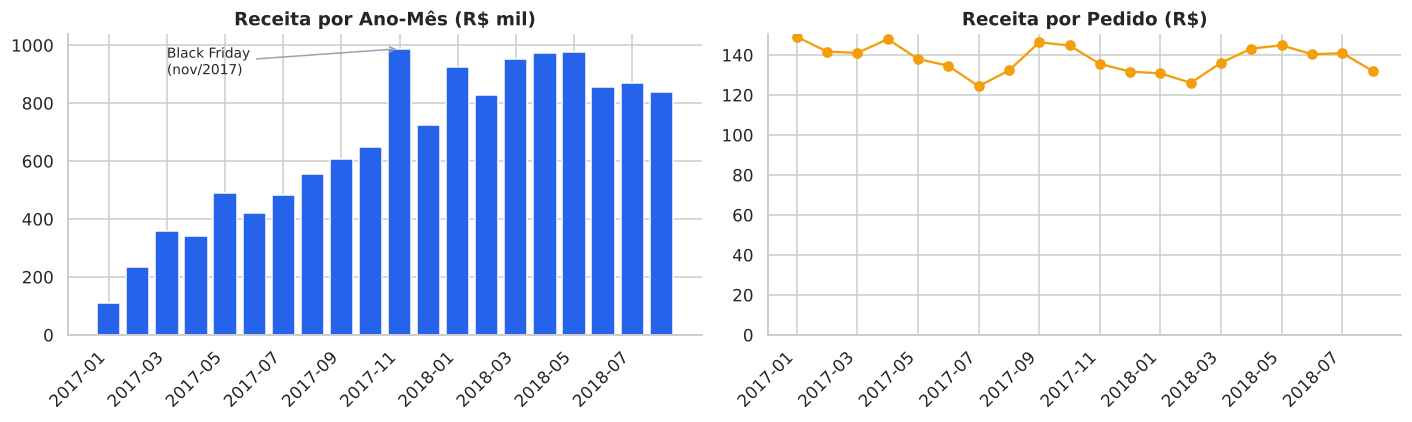

Receita jan–ago/2017: R$ 2,993,456  |  jan–ago/2018: R$ 7,218,125  |  crescimento: 141%
Receita por Pedido no período: R$ 138.09 (variação estável: 124 a 149)


In [2]:
mensal = (base.groupby("ano_mes")
          .agg(pedidos=("order_id", "count"), receita=("receita_itens", "sum"))
          .assign(ticket=lambda d: d.receita / d.pedidos))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].bar(mensal.index, mensal.receita / 1e3, color=AZUL)
ax[0].set_title("Receita por Ano-Mês (R$ mil)")
ax[0].set_xticks(range(0, len(mensal), 2)); ax[0].set_xticklabels(mensal.index[::2], rotation=45, ha="right")
ax[0].annotate("Black Friday\n(nov/2017)", xy=("2017-11", mensal.loc["2017-11", "receita"] / 1e3),
               xytext=(2, 900), arrowprops=dict(arrowstyle="->", color=CINZA), fontsize=9)

ax[1].plot(mensal.index, mensal.ticket, marker="o", color=LARANJA)
ax[1].set_title("Receita por Pedido (R$)")
ax[1].set_ylim(0, None)
ax[1].set_xticks(range(0, len(mensal), 2)); ax[1].set_xticklabels(mensal.index[::2], rotation=45, ha="right")
plt.tight_layout(); plt.savefig("../reports/figures/01_vendas_mensais.png", bbox_inches="tight"); plt.show()

q = mensal.loc["2017-01":"2017-08"].receita.sum(), mensal.loc["2018-01":"2018-08"].receita.sum()
print(f"Receita jan–ago/2017: R$ {q[0]:,.0f}  |  jan–ago/2018: R$ {q[1]:,.0f}  |  crescimento: {q[1]/q[0]-1:.0%}")
print(f"Receita por Pedido no período: R$ {mensal.ticket.mean():,.2f} (variação estável: {mensal.ticket.min():.0f} a {mensal.ticket.max():.0f})")

## 2. Categorias

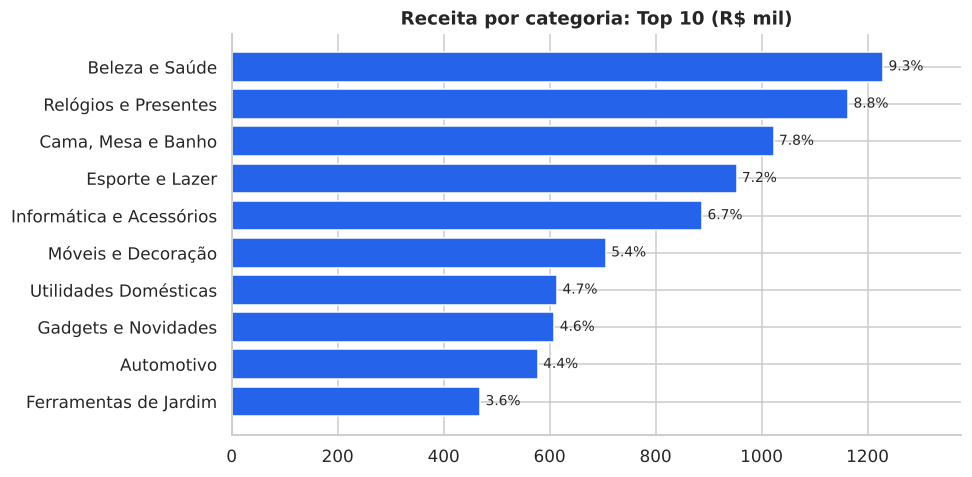

Categorias: 74  |  Top 10 = 62% da receita  |  Top 20 = 84%


,receita,pedidos,pct,acum
categoria,,,,
Beleza e Saúde,"1,229,557.50",8610,0.09,0.09
Relógios e Presentes,"1,163,465.91",5491,0.09,0.18
"Cama, Mesa e Banho","1,022,955.77",9267,0.08,0.26
Esporte e Lazer,"952,840.40",7513,0.07,0.33
Informática e Acessórios,"888,055.59",6518,0.07,0.40
Móveis e Decoração,"706,237.17",6258,0.05,0.45
Utilidades Domésticas,"614,341.62",5734,0.05,0.50
Gadgets e Novidades,"609,158.00",3552,0.05,0.55
Automotivo,"577,838.39",3802,0.04,0.59


In [3]:
itens = pd.read_sql("SELECT * FROM vw_items_enriched", con)
itens["categoria"] = traduzir(itens.categoria)
esc = base[["order_id"]]
cat = (itens.merge(esc, on="order_id")
       .groupby("categoria").agg(receita=("price", "sum"), pedidos=("order_id", "nunique"))
       .assign(ticket_item=lambda d: d.receita / d.pedidos)
       .sort_values("receita", ascending=False))
cat["pct"] = cat.receita / cat.receita.sum()
cat["acum"] = cat.pct.cumsum()

top = cat.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(top.index, top.receita / 1e3, color=AZUL)
for i, (r, p) in enumerate(zip(top.receita / 1e3, top.pct)):
    ax.text(r + 10, i, f"{p:.1%}", va="center", fontsize=9)
ax.set_title("Receita por categoria: Top 10 (R$ mil)"); ax.set_xlim(0, top.receita.max() / 1e3 * 1.12)
plt.tight_layout(); plt.savefig("../reports/figures/02_categorias.png", bbox_inches="tight"); plt.show()

print(f"Categorias: {len(cat)}  |  Top 10 = {cat.acum.iloc[9]:.0%} da receita  |  Top 20 = {cat.acum.iloc[19]:.0%}")
cat.head(10)[["receita", "pedidos", "pct", "acum"]]

## 3. Logística: prazo, atraso e frete por estado
O atraso é medido contra a **data estimada** informada ao cliente no momento da compra.

Entrega média: 12.5 dias  |  Atrasados: 8.1%
Prazo estimado médio: 24.3 dias  vs  real 12.5 dias (a estimativa é conservadora)


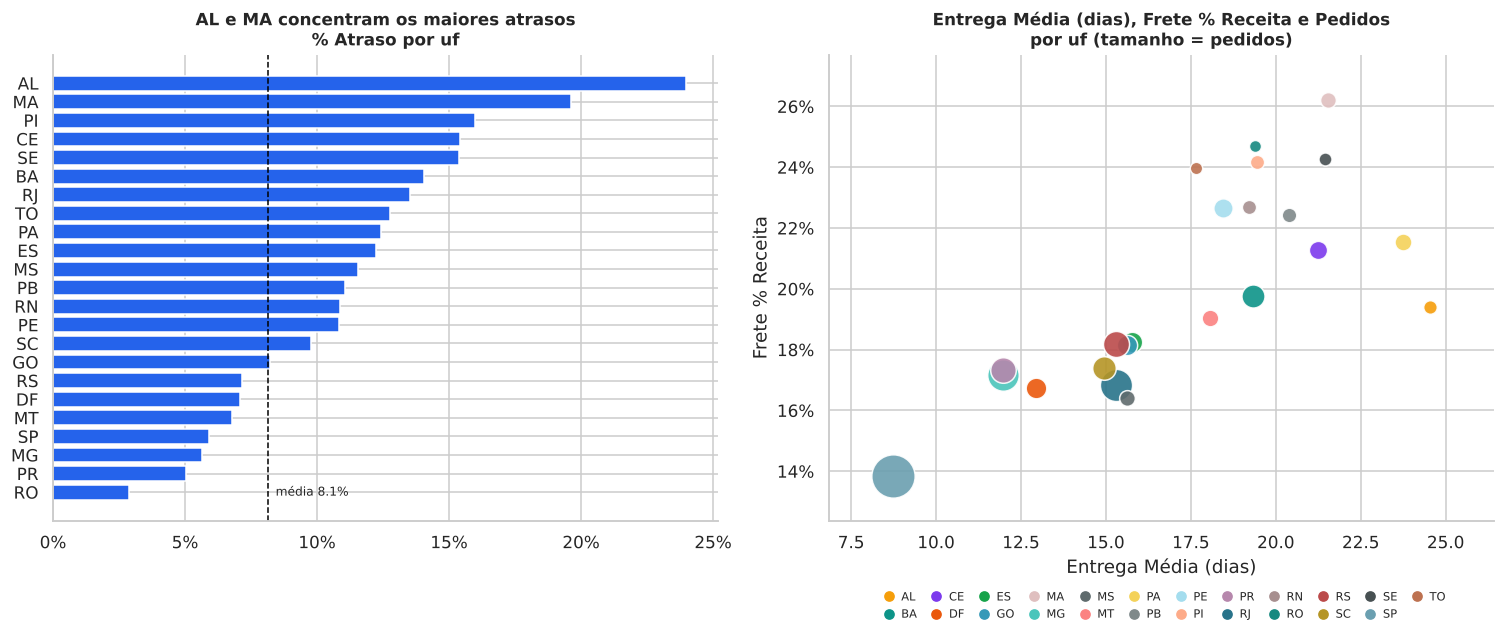

,pedidos,dias_entrega,pct_atraso,frete_pct,nota
customer_state,,,,,
AL,396,24.52,0.24,0.19,3.85
MA,713,21.54,0.20,0.26,3.83
PI,475,19.44,0.16,0.24,3.99
CE,1273,21.24,0.15,0.21,3.94
SE,332,21.44,0.15,0.24,3.90
BA,3253,19.33,0.14,0.20,3.93
RJ,12310,15.30,0.14,0.17,3.97
TO,274,17.66,0.13,0.24,4.15


In [4]:
uf = (base.dropna(subset=["dias_entrega"])
      .groupby("customer_state")
      .agg(pedidos=("order_id", "count"), dias_entrega=("dias_entrega", "mean"),
           pct_atraso=("flag_atrasado", "mean"), nota=("review_score", "mean"),
           frete_pct=("frete_total", "sum"), receita=("receita_itens", "sum"))
      .assign(frete_pct=lambda d: d.frete_pct / d.receita)
      .query("pedidos >= 200").sort_values("pct_atraso", ascending=False))

geral = base.dropna(subset=["dias_entrega"])
print(f"Entrega média: {geral.dias_entrega.mean():.1f} dias  |  Atrasados: {geral.flag_atrasado.mean():.1%}")
est = (pd.to_datetime(geral.data_estimada) - geral.data_compra).dt.days
print(f"Prazo estimado médio: {est.mean():.1f} dias  vs  real {geral.dias_entrega.mean():.1f} dias (a estimativa é conservadora)")

# Cores como no Power BI: barras em azul; cada UF usa a cor do tema Olist Portfolio (ordem alfabética das 27 UFs)
UFS = ["AC", "AL", "AM", "AP", "BA", "CE", "DF", "ES", "GO", "MA", "MG", "MS", "MT", "PA", "PB", "PE", "PI", "PR", "RJ", "RN", "RO", "RR", "RS", "SC", "SE", "SP", "TO"]
PALETA_UF = ["#2563eb", "#f59e0b", "#dc2626", "#94a3b8", "#0d9488", "#7c3aed", "#ea580c", "#16a34a", "#3599B8", "#DFBFBF", "#4AC5BB", "#5F6B6D", "#FB8281",
             "#F4D25A", "#7F898A", "#A4DDEE", "#FDAB89", "#B687AC", "#28738A", "#A78F8F", "#168980", "#293537", "#BB4A4A", "#B59525", "#475052", "#6A9FB0", "#BD7150"]
COR_UF = dict(zip(UFS, PALETA_UF))

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
ordem = uf.sort_values("pct_atraso")
ax[0].barh(ordem.index, ordem.pct_atraso, color=AZUL)
ax[0].axvline(geral.flag_atrasado.mean(), color="black", ls="--", lw=1)
ax[0].text(geral.flag_atrasado.mean() + .003, 0, f"média {geral.flag_atrasado.mean():.1%}", fontsize=8, va="center")
ax[0].xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax[0].set_title("AL e MA concentram os maiores atrasos\n% Atraso por uf", fontsize=11)

for s, r in uf.iterrows():
    ax[1].scatter(r.dias_entrega, r.frete_pct, s=np.sqrt(r.pedidos) * 4, color=COR_UF[s], edgecolor="white", alpha=.9)
ax[1].margins(0.12)
ax[1].yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax[1].set_xlabel("Entrega Média (dias)"); ax[1].set_ylabel("Frete % Receita")
ax[1].set_title("Entrega Média (dias), Frete % Receita e Pedidos\npor uf (tamanho = pedidos)", fontsize=11)
ax[1].legend(handles=[Line2D([], [], marker="o", ls="", color=COR_UF[s], label=s, markersize=6) for s in uf.index.sort_values()],
             ncol=12, fontsize=7.5, loc="upper center", bbox_to_anchor=(.5, -.13), frameon=False, handletextpad=.1, columnspacing=.7)
plt.tight_layout(); plt.savefig("../reports/figures/03_logistica_uf.png", bbox_inches="tight"); plt.show()

uf.head(8)[["pedidos", "dias_entrega", "pct_atraso", "frete_pct", "nota"]]

> **Nota sobre o frete.** O gráfico usa a razão `soma(frete) / soma(preço)` por estado. A média das razões pedido a pedido seria inflada por pedidos baratos em que o frete passa do preço do produto (no AL daria ~47% contra ~19% pela razão de somas). A mediana por pedido confirma a diferença regional: ~33% no AL e ~38% no MA, contra ~24% no RJ e ~19% em SP.

## 4. Atraso x satisfação do cliente
A hipótese central: **atrasar a entrega derruba a nota.** Primeiro o visual, depois o teste estatístico.

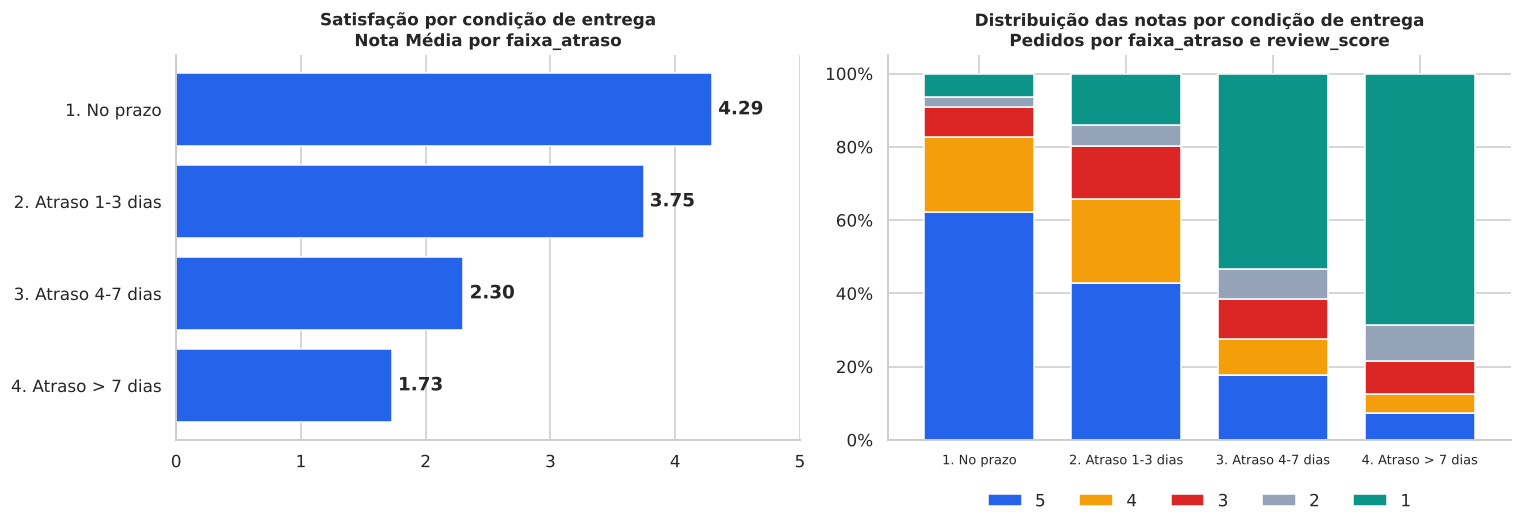

,pedidos,nota,pct_baixas
faixa,,,
1. No prazo,87963,4.29,0.09
2. Atraso 1-3 dias,2590,3.75,0.20
3. Atraso 4-7 dias,1787,2.30,0.62
>7 dias,3220,1.73,0.78


In [5]:
sat = base.dropna(subset=["review_score", "dias_atraso"]).copy()
sat["faixa"] = pd.cut(sat.dias_atraso, [-np.inf, 0, 3, 7, np.inf],
                      labels=["1. No prazo", "2. Atraso 1-3 dias", "3. Atraso 4-7 dias", "4. Atraso > 7 dias"])
res = sat.groupby("faixa", observed=True).agg(pedidos=("order_id", "count"), nota=("review_score", "mean"),
                                              pct_baixas=("review_score", lambda s: (s <= 2).mean()))

# Cores e nomes como no Power BI: barras em azul; notas 5=azul, 4=âmbar, 3=vermelho, 2=cinza, 1=verde-água
COR_NOTA = {5: AZUL, 4: LARANJA, 3: VERMELHO, 2: CINZA, 1: VERDE_AGUA}
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].barh(res.index.astype(str), res.nota, color=AZUL); ax[0].invert_yaxis()
for i, v in enumerate(res.nota): ax[0].text(v + .05, i, f"{v:.2f}", va="center", fontweight="bold")
ax[0].set_xlim(0, 5); ax[0].set_title("Satisfação por condição de entrega\nNota Média por faixa_atraso", fontsize=11)

dist = pd.crosstab(sat.faixa, sat.review_score, normalize="index")
dist = dist[sorted(dist.columns, reverse=True)]          # 5 embaixo ... 1 no topo, como no Power BI
dist.plot(kind="bar", stacked=True, ax=ax[1], color=[COR_NOTA[int(n)] for n in dist.columns], width=.75)
ax[1].yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax[1].set_title("Distribuição das notas por condição de entrega\nPedidos por faixa_atraso e review_score", fontsize=11); ax[1].set_xlabel("")
ax[1].legend([str(int(n)) for n in dist.columns], ncol=5, loc="upper center", bbox_to_anchor=(.5, -.1), frameon=False)
ax[1].tick_params(axis="x", rotation=0, labelsize=8.5); ax[0].tick_params(axis="x", rotation=0)
ax[0].grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig("../reports/figures/04_atraso_vs_nota.png", bbox_inches="tight"); plt.show()
res

In [6]:
# ---- Testes estatísticos ----
no_prazo = sat.loc[sat.dias_atraso <= 0, "review_score"]
atrasado = sat.loc[sat.dias_atraso > 0, "review_score"]

# Notas são ordinais (1–5): usar teste não paramétrico
u, p = stats.mannwhitneyu(atrasado, no_prazo, alternative="less")
cliff = 2 * u / (len(atrasado) * len(no_prazo)) - 1      # tamanho de efeito (Cliff's delta)
rho, p_rho = stats.spearmanr(sat.dias_atraso.clip(lower=0), sat.review_score)

print(f"Nota média  | no prazo: {no_prazo.mean():.2f}  | atrasado: {atrasado.mean():.2f}  | diferença: {atrasado.mean()-no_prazo.mean():.2f}")
print(f"Mann-Whitney U (atrasado < no prazo): p = {p:.2e}")
print(f"Tamanho de efeito (Cliff's delta): {cliff:.2f}   (|d|>0.47 = efeito grande)")
print(f"Spearman (dias de atraso x nota): rho = {rho:.2f}, p = {p_rho:.2e}")

# ---- Quanto custa o atraso em experiência? ----
baixa_prazo = (no_prazo <= 2).mean(); baixa_atraso = (atrasado <= 2).mean()
excesso = (baixa_atraso - baixa_prazo) * len(atrasado)
total_baixas = (sat.review_score <= 2).sum()
print(f"\nNotas 1–2: {baixa_prazo:.1%} no prazo vs {baixa_atraso:.1%} com atraso")
print(f"Pedidos atrasados = {len(atrasado)/len(sat):.1%} da base, mas geram {(atrasado<=2).sum()/total_baixas:.1%} de todas as notas baixas")
print(f"Excesso de notas 1–2 vs. a taxa dos pedidos no prazo: ~{excesso:,.0f} ({excesso/total_baixas:.0%} de todas as notas baixas)")

Nota média  | no prazo: 4.29  | atrasado: 2.55  | diferença: -1.74
Mann-Whitney U (atrasado < no prazo): p = 0.00e+00
Tamanho de efeito (Cliff's delta): -0.56   (|d|>0.47 = efeito grande)
Spearman (dias de atraso x nota): rho = -0.30, p = 0.00e+00

Notas 1–2: 9.2% no prazo vs 54.5% com atraso
Pedidos atrasados = 7.9% da base, mas geram 33.8% de todas as notas baixas
Excesso de notas 1–2 vs. a taxa dos pedidos no prazo: ~3,438 (28% de todas as notas baixas)


> **Cuidado com causalidade.** Atraso e nota baixa andam juntos de forma muito forte, mas é uma associação observacional. Atrasos também correlacionam com outros problemas (produto errado, extravio) que podem ajudar a puxar a nota. Para a decisão de negócio, o dado já basta para priorizar a logística, mas é bom registrar essa limitação.

## 5. Vendedores: concentração de receita

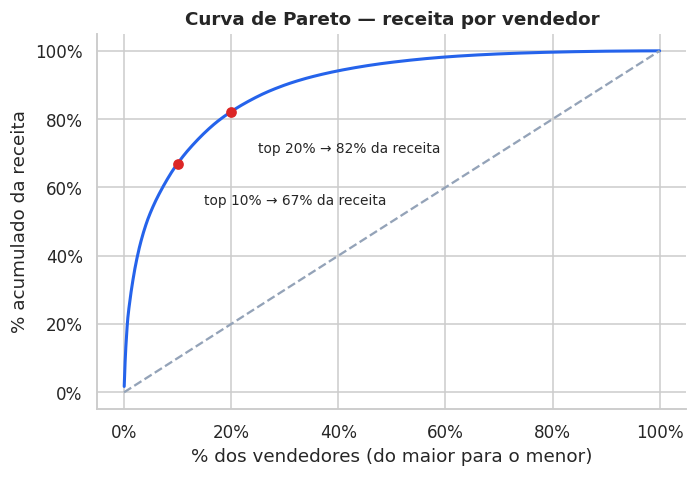

Vendedores ativos: 2,945  |  Top 20% = 82%  |  Metade final dos vendedores = 3.4% da receita
Índice de Gini da receita: 0.79


In [7]:
vend = (pd.read_sql("SELECT order_id, seller_id, price FROM order_items", con)
        .merge(base[["order_id"]], on="order_id")
        .groupby("seller_id").price.sum().sort_values(ascending=False))
cum = vend.cumsum() / vend.sum()
x = np.arange(1, len(vend) + 1) / len(vend)

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(x, cum.values, color=AZUL, lw=2); ax.plot([0, 1], [0, 1], color=CINZA, ls="--")
for pct in (0.1, 0.2):
    v = cum.iloc[int(pct * len(vend)) - 1]
    ax.scatter(pct, v, color=VERMELHO, zorder=3); ax.annotate(f"top {pct:.0%} → {v:.0%} da receita", (pct, v), xytext=(pct + .05, v - .12), fontsize=9)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xlabel("% dos vendedores (do maior para o menor)"); ax.set_ylabel("% acumulado da receita")
ax.set_title("Curva de Pareto — receita por vendedor")
plt.tight_layout(); plt.savefig("../reports/figures/05_pareto_vendedores.png", bbox_inches="tight"); plt.show()

gini = 2 * np.sum((cum.values[1:] + cum.values[:-1]) / 2 * np.diff(x)) - 1
print(f"Vendedores ativos: {len(vend):,}  |  Top 20% = {cum.iloc[int(.2*len(vend))-1]:.0%}  |  Metade final dos vendedores = {1-cum.iloc[len(vend)//2-1]:.1%} da receita")
print(f"Índice de Gini da receita: {gini:.2f}")

## 6. Clientes: recompra e segmentação RFM
Com ~97% dos clientes comprando uma única vez, o RFM clássico (quintis de frequência) não funciona. Adaptei as regras: **recorrentes** são tratados à parte, e quem comprou só uma vez é segmentado por **recência** e **valor**.

Clientes únicos: 93,104
Pedidos por cliente: {1: '97.0%', 2: '2.8%', '3+': '0.2%'}
Receita dos recorrentes (2+ pedidos): 5.5% da receita, com 3.0% dos clientes


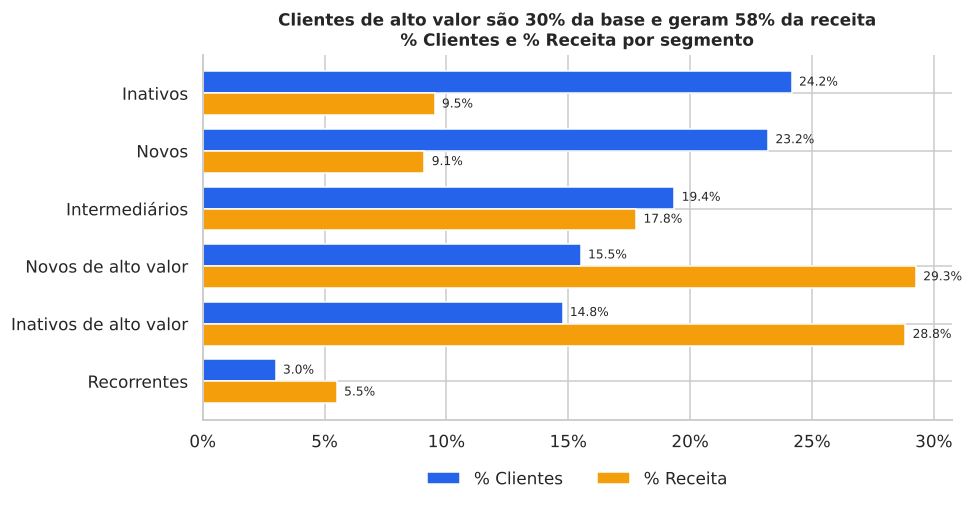

,clientes,pct_clientes,pct_receita,ticket,recencia
segmento,,,,,
Novos de alto valor,14443,0.16,0.29,267.08,91.95
Inativos de alto valor,13748,0.15,0.29,276.40,392.22
Intermediários,18019,0.19,0.18,130.11,219.84
Inativos,22503,0.24,0.10,55.75,393.30
Novos,21602,0.23,0.09,55.52,89.90
Recorrentes,2789,0.03,0.06,260.08,220.11


In [8]:
cli = (base.groupby("customer_unique_id")
       .agg(frequencia=("order_id", "count"), monetario=("receita_itens", "sum"), ultima=("data_compra", "max")))
ref = base.data_compra.max() + pd.Timedelta(days=1)
cli["recencia"] = (ref - cli.ultima).dt.days

dist_freq = cli.frequencia.clip(upper=3).value_counts(normalize=True).sort_index()
print(f"Clientes únicos: {len(cli):,}")
print("Pedidos por cliente:", {("3+" if k == 3 else int(k)): f"{v:.1%}" for k, v in dist_freq.items()})
print(f"Receita dos recorrentes (2+ pedidos): {cli.loc[cli.frequencia>=2,'monetario'].sum()/cli.monetario.sum():.1%} da receita, "
      f"com {(cli.frequencia>=2).mean():.1%} dos clientes")

# pontuações por quintil (5 = melhor)
cli["R"] = pd.qcut(cli.recencia.rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
cli["M"] = pd.qcut(cli.monetario.rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

def segmento(r):
    if r.frequencia >= 2:            return "Recorrentes"
    if r.R >= 4 and r.M >= 4:        return "Novos de alto valor"
    if r.R >= 4:                     return "Novos"
    if r.R <= 2 and r.M >= 4:        return "Inativos de alto valor"
    if r.R <= 2:                     return "Inativos"
    return "Intermediários"
cli["segmento"] = cli.apply(segmento, axis=1)

seg = (cli.groupby("segmento")
       .agg(clientes=("frequencia", "size"), receita=("monetario", "sum"), ticket=("monetario", "mean"), recencia=("recencia", "mean"))
       .assign(pct_clientes=lambda d: d.clientes / d.clientes.sum(), pct_receita=lambda d: d.receita / d.receita.sum())
       .sort_values("receita", ascending=False))

# Como no Power BI: barras agrupadas, % Clientes (azul) e % Receita (âmbar), maior % de clientes no topo
ordem = seg.sort_values("pct_clientes")
alto = seg.loc[["Novos de alto valor", "Inativos de alto valor"]]
y = np.arange(len(ordem)); h = .38
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(y + h / 2, ordem.pct_clientes, h, color=AZUL, label="% Clientes")
ax.barh(y - h / 2, ordem.pct_receita, h, color=LARANJA, label="% Receita")
for yi, a, b in zip(y, ordem.pct_clientes, ordem.pct_receita):
    ax.text(a + .003, yi + h / 2, f"{a:.1%}", va="center", fontsize=8); ax.text(b + .003, yi - h / 2, f"{b:.1%}", va="center", fontsize=8)
ax.set_yticks(y); ax.set_yticklabels(ordem.index); ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_title(f"Clientes de alto valor são {alto.pct_clientes.sum():.0%} da base e geram {alto.pct_receita.sum():.0%} da receita\n% Clientes e % Receita por segmento", fontsize=11)
ax.legend(ncol=2, loc="upper center", bbox_to_anchor=(.5, -.1), frameon=False)
plt.tight_layout(); plt.savefig("../reports/figures/06_rfm_segmentos.png", bbox_inches="tight"); plt.show()
seg[["clientes", "pct_clientes", "pct_receita", "ticket", "recencia"]]

### A experiência de entrega explica a baixa recompra?
Hipótese natural: se o atraso gera nota baixa, ele também deveria afastar o cliente. Para testar sem viés de censura, uso só clientes cuja 1ª compra ocorreu até fev/2018 (6 meses de janela) e meço a recompra em até 180 dias.

In [9]:
a = fatos[fatos.order_status == "delivered"].sort_values(["customer_unique_id", "data_compra"]).copy()
a["seq"] = a.groupby("customer_unique_id").cumcount() + 1
p1 = a[a.seq == 1][["customer_unique_id", "data_compra", "flag_atrasado", "review_score"]].rename(columns={"data_compra": "d1"})
p2 = a[a.seq == 2][["customer_unique_id", "data_compra"]].rename(columns={"data_compra": "d2"})
m = p1.merge(p2, on="customer_unique_id", how="left")
m = m[m.d1.between("2017-01-01", "2018-02-28")].copy()
m["recomprou_180d"] = ((m.d2 - m.d1).dt.days <= 180).fillna(False)
m["nota_baixa"] = m.review_score <= 2

print(f"Clientes elegíveis: {len(m):,}  |  taxa de recompra em 180 dias: {m.recomprou_180d.mean():.2%}\n")
t1 = m.groupby(m.flag_atrasado.map({0.0: "1ª entrega no prazo", 1.0: "1ª entrega atrasada"})).recomprou_180d.agg(["mean", "size"])
t2 = m.dropna(subset=["review_score"]).groupby(m.nota_baixa.map({False: "Nota 3–5 na 1ª compra", True: "Nota 1–2 na 1ª compra"})).recomprou_180d.agg(["mean", "size"])
tab = pd.concat([t1, t2]).rename(columns={"mean": "recompra_180d_%", "size": "clientes"})
tab["recompra_180d_%"] = (tab["recompra_180d_%"] * 100).round(2)
tab

Clientes elegíveis: 55,261  |  taxa de recompra em 180 dias: 3.12%



,recompra_180d_%,clientes
1ª entrega atrasada,2.79,4263
1ª entrega no prazo,3.15,50996
Nota 1–2 na 1ª compra,3.08,7206
Nota 3–5 na 1ª compra,3.13,47643


## 7. Conclusões e recomendações

### O que os dados mostram
1. **Crescimento puxado por volume, não por preço.** A receita de jan–ago/2018 foi **141% maior** que a do mesmo período de 2017 (R$ 7,2 mi vs R$ 3,0 mi), com ticket médio estável (~R$ 138). Novembro/2017 (Black Friday) foi o pico, +52% sobre outubro.
2. **Atraso é o principal fator de insatisfação.** Pedidos no prazo têm nota média 4,29; atrasados, 2,55 (efeito grande: Cliff's δ = −0,56). Só **7,9% dos pedidos** chegam atrasados, mas eles geram **33,8% de todas as notas 1–2**. O dano se concentra nos atrasos longos: com 4–7 dias, 62% das notas são baixas; acima de 7 dias, 78%.
3. **A logística falha mais no Nordeste.** AL (24%), MA (20%) e PI/CE/SE (15–16%) têm mais atraso que a média (8,1%), prazos de 19 a 25 dias e frete mais pesado (19–26% da receita, contra 14% em SP). O Norte não segue o padrão de forma uniforme: entre os estados com pelo menos 200 pedidos, RO tem ~3% de atraso, enquanto PA e TO ficam em ~12–13%.
4. **O prazo prometido é muito folgado.** A estimativa média é de ~24 dias, e a entrega real leva ~12,5. Mesmo assim, 8% atrasam: o problema está na cauda de casos extremos, não na média.
5. **Receita concentrada em poucos vendedores.** Os 20% maiores respondem por ~82% da receita; a metade final, por ~3%. Em categorias, as 10 maiores somam 62%.
6. **Quase ninguém recompra.** 97% dos clientes compraram uma única vez. Recorrentes são 3% dos clientes e 5,5% da receita.
7. **A baixa recompra não parece ser causada pela entrega.** A recompra em 180 dias é de ~3,1% com 1ª entrega no prazo e ~2,8% com atraso; entre quem deu nota baixa ou alta na 1ª compra, praticamente igual (~3,1%). O atraso machuca a nota, mas não explica sozinho a falta de retorno.

### Recomendações
| Prioridade | Ação | Base nos dados |
|---|---|---|
| 1 | **Tratar atrasos acima de 3 dias como incidente**: aviso proativo ao cliente, atendimento e compensação. | Nota cai de 3,75 (1–3 dias) para 2,30 (4–7) e 1,73 (>7) |
| 2 | **Atacar a logística de AL, MA, PI, CE, SE e BA**: rever transportadoras e rotas, e avaliar centros de distribuição. | Maiores taxas de atraso e prazos de até 25 dias |
| 3 | **Calibrar o prazo estimado por região** e testar (A/B) o efeito na conversão. | Estimativa ~2x o prazo real na média, mas com cauda de atrasos |
| 4 | **Reativar clientes inativos de alto valor** (~13,7 mil, 29% da receita histórica, ticket ~R$ 276) e fazer onboarding de novos de alto valor. | Retenção é a maior folga de receita; o gargalo não é logística |
| 5 | **Reduzir dependência de poucos vendedores**: programa de desenvolvimento para o 2º quintil e monitoramento de risco nos top. | Top 20% = 82% da receita |
| 6 | **Planejar capacidade para picos** (Black Friday). | +52% em nov/2017 |

### Limitações
- **Associação, não causalidade.** Atraso e nota baixa andam juntos, mas outros problemas (produto errado, extravio) também podem pesar na nota.
- **Receita não é lucro.** A base não tem custo nem margem; prioridades financeiras precisam desse dado.
- **Janela curta (20 meses) e marketplace de crescimento acelerado**: tendências podem refletir a expansão da empresa, não comportamento estável.
- **Por que o cliente não volta fica sem resposta.** Pode ser perfil de compra pontual, concorrência ou falta de relacionamento; a base não permite distinguir.
- **RFM adaptado**, já que quase todos têm frequência 1. Os segmentos são regras de negócio, não clusters estatísticos.
- **Atraso medido contra a data estimada** informada pela plataforma, não contra a expectativa do cliente.